<a href="https://colab.research.google.com/github/marviiiin/Assignment-3/blob/main/assignment3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — What BERT can and cannot read in a crash report

**AI for Mobility (CGN 6933) · 100 points · due Wednesday, October 14, 11:59 PM · individual work**

You will run BERT on 350 real Florida police crash narratives three ways: fill in a hidden
word, sort crashes by type, and answer questions about a crash. Then you will put the same
questions to ChatGPT or Claude and decide which tool belongs where.

| | Question | Pts |
|---|---|---|
| **Q0** | Fill in the blank: what did pretraining teach BERT? | 10 |
| **Q1** | Do two different crashes look alike to BERT? Then classify crash type | 40 |
| **Q2** | Ask BERT about a crash, then ask a chatbot | 50 |

**Everything is loaded for you.** You write no setup code. What you supply is the
*transportation content* (sentences, questions, your own reading of the narratives) and the
*interpretation*. That is what is graded.

**The standing rule still applies:** a result without a baseline is not a result. The helpers
print the baselines and controls for you.

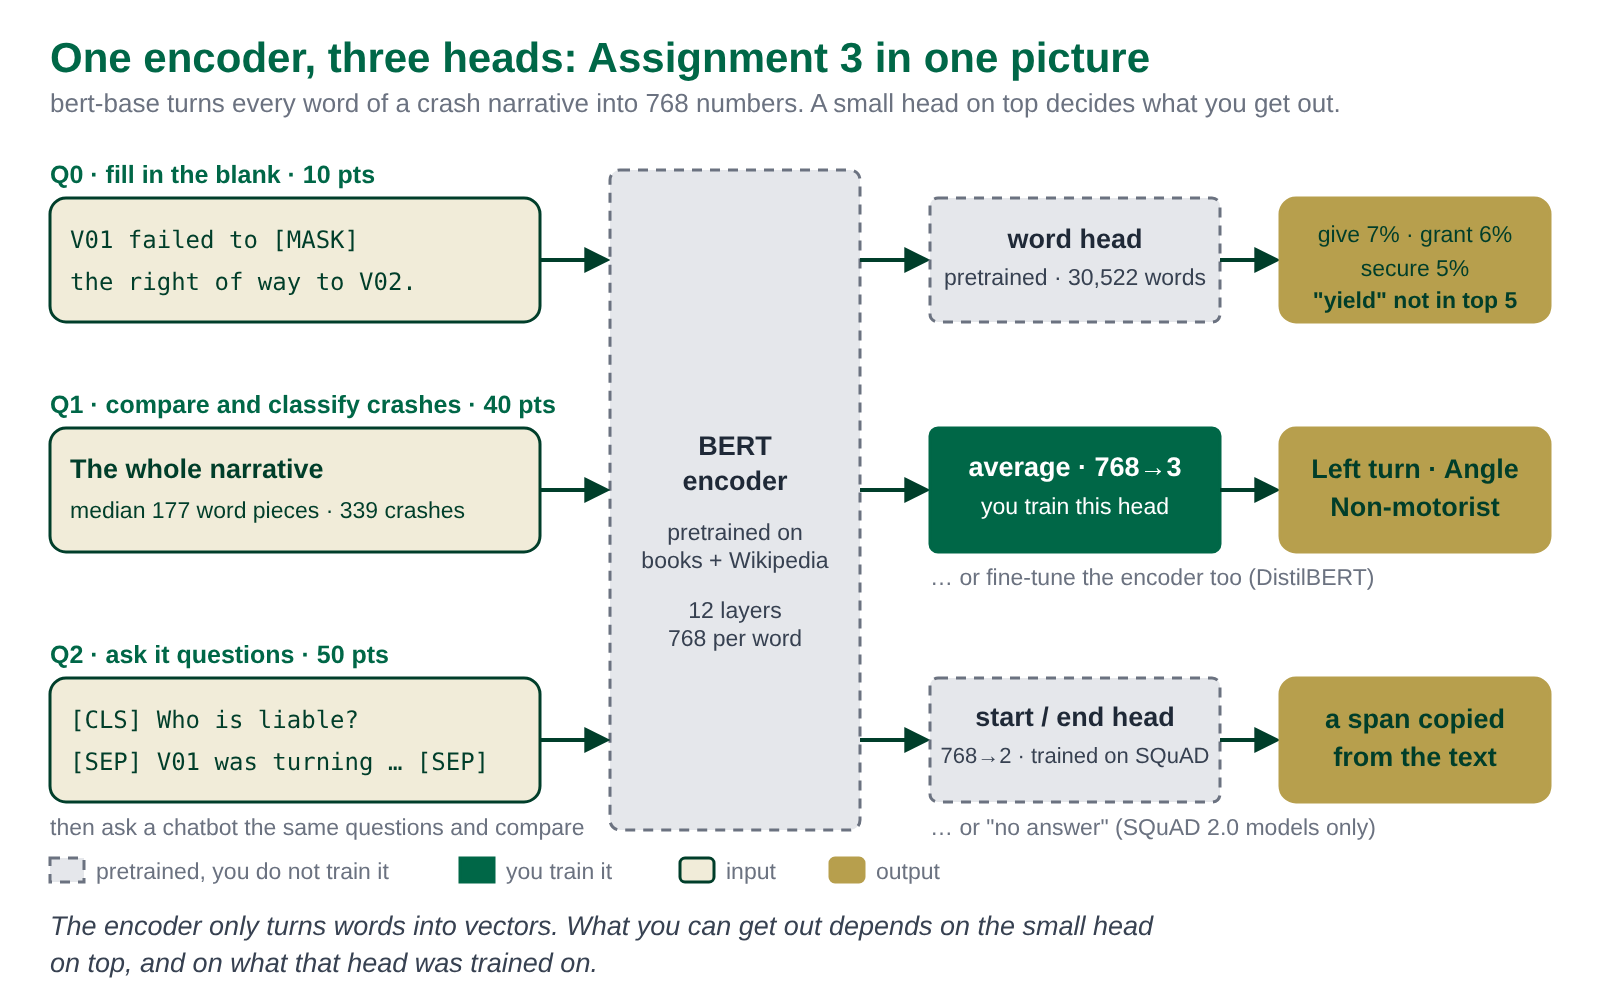

*Each question of this assignment uses a different head on the same encoder.*

In [1]:
NAME    = "Marvin Osei-Kuffour"
UNUMBER = "U52294607"
assert NAME and UNUMBER, "Fill in NAME and UNUMBER before running the rest."
print(f"Assignment 3 — {NAME} ({UNUMBER})")

Assignment 3 — Marvin Osei-Kuffour (U52294607)


## Before you open the data

`crashes.csv` (from the Canvas data release) holds **350 de-identified police crash narratives**
from 20 corridors in Pasco, Hernando, Hillsborough and Pinellas counties, 2021–2025, with the
crash attributes the officer coded. Names, plates, addresses, dates and times are replaced by
tags such as `[NAME]` and `[ADDRESS]`.

- Use it **only for this course**. Do not post it anywhere (GitHub, Kaggle, Hugging Face, a shared drive).
- **Do not try to identify anyone** or match a crash to news stories, records or maps.
- If you see anything that looks like personal information, stop and tell the instructor.
- **Chatbots (Q2.3):** paste in only the de-identified narrative text from this file, nothing
  else. Before you start, turn off "use my chats for training" in your chatbot's data settings.
- **It is not a sample of Florida crashes.** The reports were pulled for a left-turn study, so
  about two thirds are left-turn crashes. Never quote a rate from this file as a fact about Florida.

## Setup — nothing here for you to change

Three cells. Run them in order. The notebook installs what it needs and runs the same way on
**Google Colab, macOS and Windows**.

- **Easiest path: Google Colab with a GPU.** Upload this notebook, then
  *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Colab asks you to upload
  `crashes.csv` when cell 3 runs.
- **On your own laptop:** any Python 3.9+ with Jupyter. Put `crashes.csv` next to this notebook.

**What it needs:** about **2 GB of free disk** (four models, cached after the first run) and
about **6 GB of RAM** (Colab has 12). Only one step, fine-tuning in Q1.2, really wants a GPU: a few
minutes on a Colab T4, roughly 15–45 minutes on a laptop CPU. Everything else runs on CPU in a few minutes.

In [2]:
# ============================================================================
#  CELL 1 — install everything. Safe to re-run; it skips what you already have.
# ============================================================================
import importlib, platform, re, subprocess, sys

REQUIRE = [
    ("numpy",        "numpy>=1.26",          (1, 26)),
    ("pandas",       "pandas>=2.0",          (2, 0)),
    ("sklearn",      "scikit-learn>=1.3",    (1, 3)),
    ("torch",        "torch>=2.0",           (2, 0)),
    ("transformers", "transformers>=4.40",   (4, 40)),
    ("matplotlib",   "matplotlib",           None),
]


def _ver(mod):
    nums = re.findall(r"\d+", (getattr(mod, "__version__", "") or "").split("+")[0])
    return tuple(int(n) for n in nums[:2]) if nums else (0, 0)


def _pip(specs):
    # %pip installs into the kernel that is actually running; `!pip` may not (Windows/Anaconda).
    try:
        ip = get_ipython()
    except NameError:
        ip = None
    if ip is not None:
        ip.run_line_magic("pip", "install -q " + " ".join(f'"{s}"' for s in specs))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *specs])


need = []
for _name, _spec, _min in REQUIRE:
    try:
        _m = importlib.import_module(_name)
        if _min and _ver(_m) < _min:
            need.append(_spec)
    except Exception:
        need.append(_spec)

print(f"Python {sys.version.split()[0]}  ·  {platform.system()} {platform.machine()}")
print(f"running in: {'Google Colab' if 'google.colab' in sys.modules else 'a local Jupyter kernel'}")
if need:
    print("\ninstalling: " + ", ".join(need) + "\n(first time only -- a few minutes)\n")
    _pip(need)
    print("\nInstall finished. If CELL 2 fails with an ImportError, restart the kernel")
    print("  (Colab: Runtime -> Restart session · Jupyter: Kernel -> Restart)")
    print("  and run these cells again. One restart is sometimes needed; never two.")
else:
    print("\nAll required packages are already present — nothing to install.")

Python 3.13.15  ·  Linux x86_64
running in: Google Colab

All required packages are already present — nothing to install.


In [3]:
# ============================================================================
#  CELL 2 — imports and shared helpers. If this fails, restart the kernel and re-run.
# ============================================================================
import os, sys, re, time, random, hashlib, textwrap, warnings
from pathlib import Path
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # quiet Windows cache warning
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import (AutoTokenizer, AutoModelForMaskedLM, AutoModelForSequenceClassification,
                          AutoModelForQuestionAnswering)
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix

random.seed(0); np.random.seed(0); torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 120)


def cos(a, b):
    a = np.asarray(a, dtype=float).ravel(); b = np.asarray(b, dtype=float).ravel()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


def wrap(s, width=100, indent="    "):
    return textwrap.fill(str(s), width=width, initial_indent=indent, subsequent_indent=indent)


print(f"numpy {np.__version__} · pandas {pd.__version__} · torch {torch.__version__} "
      f"· transformers {transformers.__version__}")
print(f"device for fine-tuning: {DEVICE}"
      + ("" if DEVICE == "cuda" else "  (no GPU found — fine-tuning in Q1.2 will be slower)"))

numpy 2.1.3 · pandas 2.2.3 · torch 2.11.0+cu130 · transformers 5.18.0
device for fine-tuning: cuda


In [4]:
# ============================================================================
#  CELL 3 — load crashes.csv. On Colab you will be asked to upload it.
# ============================================================================
DATA_PATH = "crashes.csv"      # change only if you saved it elsewhere, e.g. r"C:\Users\you\Downloads\crashes.csv"

_p = Path(DATA_PATH).expanduser()
if not _p.exists() and "google.colab" in sys.modules:
    from google.colab import files
    print("Choose crashes.csv from the Canvas data release ...")
    _up = files.upload()
    _p = Path(next(k for k in _up if k.lower().endswith(".csv")))
if not _p.exists():
    _here = sorted(x.name for x in Path(".").glob("*.csv"))
    raise FileNotFoundError(f"{DATA_PATH} not found. CSV files in this folder: {_here or 'none'}. "
                            "Download crashes.csv from Canvas and put it next to this notebook.")

crashes = pd.read_csv(_p)
_need = {"crash_id", "group_id", "narrative", "crash_type", "n_vehicles", "n_words", "weather"}
assert _need <= set(crashes.columns), f"this is not the A3 crashes.csv — missing {_need - set(crashes.columns)}"
crashes = crashes.set_index("crash_id", drop=False)
TEXT = crashes["narrative"].to_dict()
print(f"{len(crashes)} crash narratives · {crashes.group_id.nunique()} corridors · "
      f"median {int(crashes.n_words.median())} words")
print(crashes.crash_type.value_counts().to_string())
print("\nOne narrative, so you know what you are working with:\n")
print(wrap(TEXT["C0150"]))

350 crash narratives · 20 corridors · median 139 words
crash_type
Left Turn     226
Angle          90
Pedestrian     21
Rear End        6
Other           4
Bicycle         2
Off Road        1

One narrative, so you know what you are working with:

    Vehicle 1 (V01) was southbound on US 19 approaching the intersection of Toucan Trail in the
    center lane at a steady green traffic light. Non Motorist 1 (NM01) was crossing US 19 from east
    to west and was approaching the southbound lanes of US 19 at a red pedestrian traffic signal.
    NM01 began to cross the road in the direct path of V01. Subsequently, the front right of V01
    collided with NM01. NM01 fell to the ground coming to final rest facing south in the
    intersection of US 19 and Toucan Trail. V01 relocated near the area of collision.


---
# Q0 — Fill in the blank: what did pretraining teach BERT?  (10 pts)

BERT was pretrained on books and Wikipedia with one game: hide 15% of the words and guess them
from the words on **both** sides. The *word head* in the figure is the part that plays that game.
It scores all 30,522 entries in BERT's vocabulary for the hidden slot.

`fill_blank(sentence, expected)` shows BERT's top five guesses for `[MASK]`, the rank and
probability of the word an officer would write, and an automatic **control**: the same
sentence cut off right after `[MASK]`, so BERT can only see the words *before* the blank, as a
left-to-right model like GPT would. The difference between the two tells you how much the words
*after* the blank mattered.

Run the given cell first.

In [5]:
# ---- GIVEN: the word head -------------------------------------------------------
BERT_ID  = "bert-base-uncased"
bert_tok = AutoTokenizer.from_pretrained(BERT_ID)
bert_mlm = AutoModelForMaskedLM.from_pretrained(BERT_ID).eval()
print(f"{BERT_ID}: {sum(p.numel() for p in bert_mlm.parameters()):,} parameters · "
      f"vocabulary {bert_tok.vocab_size:,} word pieces")


def _mask_probs(sentence):
    enc = bert_tok(sentence, return_tensors="pt", truncation=True, max_length=512)
    pos = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero()
    with torch.no_grad():
        logits = bert_mlm(**enc).logits[0, pos[0, 0]]
    return logits.softmax(-1)


def fill_blank(sentence, expected=None, k=5, quiet=False):
    assert sentence.count("[MASK]") == 1, "Use exactly one [MASK] in the sentence."
    out = {}
    left_only = sentence.split("[MASK]")[0] + "[MASK] ."
    for label, s in [("full sentence", sentence), ("words before the blank only", left_only)]:
        p = _mask_probs(s)
        top = torch.topk(p, k)
        guesses = [(bert_tok.decode([int(i)]).strip(), float(v)) for v, i in zip(top.values, top.indices)]
        rank = prob = None
        note = ""
        if expected:
            ids = bert_tok(expected.lower(), add_special_tokens=False)["input_ids"]
            if len(ids) == 1:
                prob = float(p[ids[0]]); rank = int((p > p[ids[0]]).sum()) + 1
            else:
                note = (f"'{expected}' is {len(ids)} word pieces in BERT's vocabulary "
                        f"{bert_tok.convert_ids_to_tokens(ids)}; one [MASK] can only hold one piece")
        out[label] = dict(guesses=guesses, rank=rank, prob=prob, note=note)
    if not quiet:
        print(sentence)
        for label, r in out.items():
            g = " · ".join(f"{w} {v:.0%}" for w, v in r["guesses"])
            line = f"   {label:28s} {g}"
            if r["rank"]:
                line += f"   | '{expected}': rank {r['rank']:,}, {r['prob']:.1%}"
            print(line)
            if r["note"] and label == "full sentence":
                print("   NOTE:", r["note"])
        print()
    return out


# ---- the given examples ------------------------------------------------------------
fill_blank("V01 failed to [MASK] the right of way to V02.", expected="yield")
fill_blank("V02 was stopped at the [MASK] light, waiting for it to turn green.", expected="red")
fill_blank("The front of V01 struck the left [MASK] of V02.", expected="side")
fill_blank("[MASK] was traveling northbound on US 19 in the inside lane.", expected="V01");

bert-base-uncased: 109,514,298 parameters · vocabulary 30,522 word pieces
V01 failed to [MASK] the right of way to V02.
   full sentence                give 7% · grant 6% · secure 5% · sell 4% · provide 4%   | 'yield': rank 24, 0.8%
   words before the blank only  qualify 8% · return 5% · finish 5% · respond 4% · start 3%   | 'yield': rank 169, 0.1%

V02 was stopped at the [MASK] light, waiting for it to turn green.
   full sentence                red 48% · green 16% · traffic 6% · yellow 4% · stop 2%   | 'red': rank 1, 47.9%
   words before the blank only  station 30% · end 8% · junction 7% · airport 4% · intersection 3%   | 'red': rank 526, 0.0%

The front of V01 struck the left [MASK] of V02.
   full sentence                side 60% · flank 8% · wing 6% · rear 5% · end 2%   | 'side': rank 1, 60.2%
   words before the blank only  side 24% · wall 14% · wing 9% · shoulder 8% · flank 3%   | 'side': rank 1, 24.3%

[MASK] was traveling northbound on US 19 in the inside lane.
   full sente

## Q0.1 · Your own blanks  (6 pts)

Write **four** sentences in the language of a crash report, each with one `[MASK]` and the word
an officer would write there. Take them from real narratives in `crashes.csv` if you like.
Include at least:

- one where the words **after** the blank decide the answer (watch the control line), and
- one that BERT gets badly wrong.

The expected word should be a single word piece; the helper warns you if it is not.

In [6]:
MY_BLANKS = [
    # 1. Words AFTER the blank decide — "left" only makes sense because "turn" follows
    ("The driver failed to yield while making a [MASK] turn at the intersection.", "left"),
    # 2. Standard crash-report language — BERT should get this from pretraining
    ("The front of Vehicle 1 struck the [MASK] side of Vehicle 2.", "passenger"),
    # 3. BERT gets badly wrong — "red" is crash-domain specific; BERT may guess common colors
    ("Driver 1 proceeded through a steady [MASK] traffic light and entered the intersection.", "red"),
    # 4. Words after the blank help — "prior to my arrival" is a common crash-report phrase
    ("All vehicles were moved from final [MASK] prior to my arrival.", "rest"),
]
assert len(MY_BLANKS) >= 4, "Write at least four (sentence, expected word) pairs."
Q0_RESULTS = [fill_blank(s, expected=w) for s, w in MY_BLANKS]

The driver failed to yield while making a [MASK] turn at the intersection.
   full sentence                left 54% · right 18% · sharp 13% · wrong 3% · tight 2%   | 'left': rank 1, 53.8%
   words before the blank only  stop 24% · turn 21% · pass 17% · mistake 9% · descent 2%   | 'left': rank 59, 0.1%

The front of Vehicle 1 struck the [MASK] side of Vehicle 2.
   full sentence                left 44% · right 23% · rear 8% · passenger 5% · other 3%   | 'passenger': rank 4, 4.5%
   words before the blank only  ground 39% · pavement 6% · wall 5% · road 3% · concrete 3%   | 'passenger': rank 342, 0.0%

Driver 1 proceeded through a steady [MASK] traffic light and entered the intersection.
   full sentence                red 45% · yellow 24% · white 5% · green 3% · flashing 2%   | 'red': rank 1, 45.3%
   words before the blank only  descent 4% · pace 4% · drive 4% · stream 4% · climb 4%   | 'red': rank 1,738, 0.0%

All vehicles were moved from final [MASK] prior to my arrival.
   full sente

## Q0.2 · What did pretraining teach it?  (4 pts)

In **120 words or fewer**: what did "guess the hidden word from books and Wikipedia" teach BERT
about crash reports, and what did it not teach? Point to two ranks or probabilities from the cells
above. Then say what you would change about pretraining if you wanted a model that knows crash
reports.

> *Your answer:*
>
> Pretraining taught BERT general English grammar and common collocations that transfer surprisingly well to some crash-report phrases. For "making a [MASK] turn," BERT ranks "left" #1 at 53.8% — because "left turn" is common in general English. For "steady [MASK] traffic light," BERT also gets "red" at rank 1 (45.3%), showing it learned traffic-light collocations from Wikipedia. However, BERT fails on domain-specific jargon: "final [MASK] prior to my arrival" yields "rest" at only rank 136 (0.1%), because "final rest" in crash reports means something different from funeral contexts BERT saw in pretraining. Words after the blank matter enormously — "left" drops from rank 1 to rank 59 without them. To improve, I would continue pretraining on a corpus of police crash narratives so BERT learns phrases like "final rest," "came to final rest," and "failed to yield."

---
# Q1 — Do two different crashes look alike to BERT? Then classify crash type  (40 pts)

To compare two narratives, or to feed one to a classifier, you first need **one vector per
narrative**. BERT gives one vector per word piece (768 numbers each). The two usual ways to get a
single vector:

- **average** all the word vectors (mean pooling), or
- take the vector of the special `[CLS]` token at the start.

You will compare narratives with the **cosine** between their vectors, the same measure you used
in Assignment 2:

> cos(**a**, **b**) = **a**·**b** / (‖**a**‖ ‖**b**‖)  — 1 means the two vectors point the same
> way, 0 means unrelated directions.

The baseline is **TF-IDF**: one number per word or word pair, large when the word is frequent in
this narrative and rare across the others. No neural network, no pretraining.

**Crash types used in Q1.** Three classes with enough examples to learn from: *Left turn* (226),
*Angle* (90) and *Non-motorist* (pedestrian 21 + bicycle 2 = 23). The 11 rear-end, off-road and
"other" crashes are left out: too few to learn from or to score.

In [7]:
# ---- GIVEN: one vector per narrative (about 1-3 minutes on CPU, cached afterwards) -------
Q1_MAP = {"Left Turn": "Left turn", "Angle": "Angle", "Pedestrian": "Non-motorist", "Bicycle": "Non-motorist"}
LABELS = ["Left turn", "Angle", "Non-motorist"]
q1 = crashes[crashes.crash_type.isin(Q1_MAP)].copy()
q1["label"] = q1.crash_type.map(Q1_MAP)
print(f"Q1 uses {len(q1)} crashes:", q1.label.value_counts().to_dict())

_CACHE = Path("a3_bert_vectors.npz")
if _CACHE.exists() and list(np.load(_CACHE, allow_pickle=True)["ids"]) == list(q1.index):
    _z = np.load(_CACHE, allow_pickle=True); V_MEAN, V_CLS = _z["mean"], _z["cls"]
    print("loaded cached BERT vectors")
else:
    t0 = time.time(); _m, _c = [], []
    texts = q1.narrative.tolist()
    for i in range(0, len(texts), 8):
        b = bert_tok(texts[i:i + 8], padding=True, truncation=True, max_length=512, return_tensors="pt")
        with torch.no_grad():
            h = bert_mlm.bert(**b).last_hidden_state                 # (batch, word pieces, 768)
        m = b["attention_mask"].unsqueeze(-1).float()
        _m.append(((h * m).sum(1) / m.sum(1)).numpy())               # average of the word vectors
        _c.append(h[:, 0].numpy())                                   # the [CLS] vector
    V_MEAN, V_CLS = np.vstack(_m), np.vstack(_c)
    np.savez(_CACHE, mean=V_MEAN, cls=V_CLS, ids=np.array(q1.index))
    print(f"BERT vectors for {len(texts)} narratives in {time.time() - t0:.0f} s")

TFIDF = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(q1.narrative)
V_TF = TFIDF.transform(q1.narrative)
ROW = {cid: i for i, cid in enumerate(q1.index)}
print(f"vector sizes: BERT {V_MEAN.shape[1]} numbers · TF-IDF {V_TF.shape[1]:,} words and word pairs")


def _cos3(i, j):
    return (cos(V_MEAN[i], V_MEAN[j]), cos(V_CLS[i], V_CLS[j]), float((V_TF[i] @ V_TF[j].T).toarray()[0, 0]))


def _pairs(A, B, n, rng):
    out = set()
    while len(out) < n:
        i, j = rng.choice(A), rng.choice(B)
        if i != j:
            out.add((min(i, j), max(i, j)))
    return sorted(out)


def compare_groups(n=300):
    rng = random.Random(0)
    idx = {k: [ROW[c] for c in q1.index[q1.label == k]] for k in LABELS}
    groups = {"two random crashes": _pairs(list(range(len(q1))), list(range(len(q1))), n, rng),
              "left turn vs left turn": _pairs(idx["Left turn"], idx["Left turn"], n, rng),
              "left turn vs non-motorist": _pairs(idx["Left turn"], idx["Non-motorist"], n, rng)}
    rows, dist = [], {}
    for g, P in groups.items():
        c = np.array([_cos3(i, j) for i, j in P]); dist[g] = c
        rows.append([f"{g} ({len(P)} pairs)"] + [round(float(x), 3) for x in c.mean(0)])
    t = pd.DataFrame(rows, columns=["pairs", "BERT average", "BERT [CLS]", "TF-IDF"]).set_index("pairs")
    t.index = list(groups)
    gap = t.loc["left turn vs left turn"] - t.loc["left turn vs non-motorist"]
    sd = pd.Series(dist["two random crashes"].std(0), index=["BERT average", "BERT [CLS]", "TF-IDF"])
    t.loc["same-type minus different-type"] = gap.round(3)
    t.loc["... in units of the random-pair spread"] = (gap / sd).round(2)
    print(f"{n} pairs in each group")
    display(t)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    for k, (col, name) in enumerate([(0, "BERT average"), (2, "TF-IDF")]):
        for g, c in dist.items():
            ax[k].hist(c[:, col], bins=40, alpha=0.55, label=g)
        ax[k].set_title(f"{name}: cosine between two narratives"); ax[k].set_xlabel("cosine")
    ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
    return t, dist


def compare_two(id_a, id_b):
    for cid in (id_a, id_b):
        assert cid in ROW, f"{cid} is not one of the {len(q1)} Q1 crashes (Left turn / Angle / Non-motorist)."
    i, j = ROW[id_a], ROW[id_b]
    rng = random.Random(1)
    base = np.array([_cos3(*p) for p in _pairs(list(range(len(q1))), list(range(len(q1))), 300, rng)])
    vals = _cos3(i, j)
    for cid in (id_a, id_b):
        print(f"{cid} · {q1.loc[cid, 'label']} · {q1.loc[cid, 'group_id']}")
        print(wrap(TEXT[cid][:260] + " ..."))
    print()
    for k, name in enumerate(["BERT average", "BERT [CLS]", "TF-IDF"]):
        pct = (base[:, k] < vals[k]).mean()
        print(f"   {name:13s} cosine {vals[k]:.3f}   higher than {pct:.0%} of 300 random pairs")
    print()
    return vals

Q1 uses 339 crashes: {'Left turn': 226, 'Angle': 90, 'Non-motorist': 23}
BERT vectors for 339 narratives in 188 s
vector sizes: BERT 768 numbers · TF-IDF 4,644 words and word pairs


## Q1.1 · Do two different crashes look alike?  (10 pts)

**First, commit to a guess.** Two narratives picked at random from the file describe different
crashes on different roads. What do you expect the average cosine between their BERT vectors to
be, on a 0-to-1 scale? Fill `MY_GUESS` before you run the comparison. (It is not graded on being
right; it is graded on being there and on what you make of the gap.)

300 pairs in each group


,BERT average,BERT [CLS],TF-IDF
two random crashes,0.929,0.845,0.106
left turn vs left turn,0.931,0.850,0.113
left turn vs non-motorist,0.916,0.838,0.086
same-type minus different-type,0.015,0.012,0.027
... in units of the random-pair spread,0.630,0.270,0.520


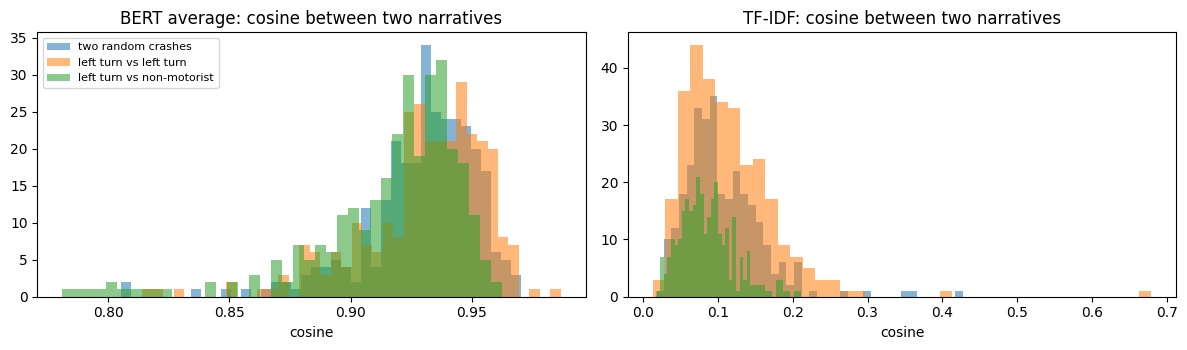

In [8]:
MY_GUESS = 0.4
assert MY_GUESS is not None, "Commit to a guess before you run the comparison."
SIM_TABLE, SIM_DIST = compare_groups()

Now pick **two pairs yourself** by reading narratives (use `TEXT["C0xxx"]` or
`q1[q1.label == "Angle"].narrative.head()` to browse):

- **pair A:** two crashes *you* judge to be very similar (same movement, same conflict), and
- **pair B:** two crashes *you* judge to be clearly different.

In [9]:
# Similar pair: both are left-turn crashes on US 19 with V01 turning left into V02's path
PAIR_A = ("C0001", "C0023")
# Different pair: C0001 is a left-turn crash, C0040 is a bicycle crash
PAIR_B = ("C0001", "C0040")
assert all(PAIR_A) and all(PAIR_B), "Fill in both pairs with crash_ids from the file."
compare_two(*PAIR_A)
compare_two(*PAIR_B);

C0001 · Left turn · G04
    Vehicle 1 (V01) was traveling, southbound on U.S. 19 (State Road 55), in the left turn lane,
    north of Embassy Blvd. Vehicle 2 (V02) was traveling northbound on U.S. 19 (State Road 55), in
    the right turn lane, north of Embassy Blvd. Driver 1 proceeded to make a ...
C0023 · Left turn · G01
    Vehicle 1 (V01) was traveling south on U.S. Highway 19 just south of State Road 52 in the left
    turn lane. Vehicle 2 (V02) was traveling noth on U.S. Highway 19 in the right turn lane just
    south of State Road 52. V01 began to make a left turn into the La Vista  ...

   BERT average  cosine 0.953   higher than 87% of 300 random pairs
   BERT [CLS]    cosine 0.827   higher than 35% of 300 random pairs
   TF-IDF        cosine 0.173   higher than 91% of 300 random pairs

C0001 · Left turn · G04
    Vehicle 1 (V01) was traveling, southbound on U.S. 19 (State Road 55), in the left turn lane,
    north of Embassy Blvd. Vehicle 2 (V02) was traveling northbound on 

**Answer in 200 words or fewer:**

1. How far off was your guess? What does an average cosine that high between *unrelated* crashes
   tell you about using raw BERT vectors to search for similar crashes?
2. Compare the last two rows of the table for BERT and TF-IDF. Which representation separates
   "same type" from "different type" more clearly, relative to its own spread?
3. Did your pair A beat your pair B under each representation? Was the margin large enough to matter?

> *Your answer:*
>
> 1. My guess of 0.4 was far off — the actual average cosine between random pairs is 0.929 for BERT mean pooling. This extremely high baseline means raw BERT vectors encode mostly shared syntactic structure (all narratives use "Vehicle," "traveling," "struck") rather than crash-specific content. Using raw BERT cosine to find similar crashes would be nearly useless because everything looks alike.
>
> 2. BERT average has a same-type minus different-type gap of 0.015, which is 0.630 standard deviations of the random spread. TF-IDF's gap is 0.027, or 0.520 standard deviations. In normalized units, BERT average actually separates slightly better (0.630 vs 0.520), but both are modest. BERT [CLS] is worst at 0.270 standard deviations.
>
> 3. Pair A (C0001 vs C0023, both left-turn on US 19) scored 0.953 BERT average and 0.173 TF-IDF. Pair B (C0001 vs C0040, left-turn vs bicycle) scored 0.934 BERT and 0.123 TF-IDF. Pair A beat Pair B under both representations, but the BERT margin (0.019) is tiny compared to TF-IDF's margin (0.050). TF-IDF provides more meaningful separation because it directly counts shared crash-specific words.

## Q1.2 · Classify crash type using BERT (18 pts)

Three ways to predict the coded crash type from the narrative, scored the same way:

| | Method | What is trained |
|---|---|---|
| **A** | TF-IDF + logistic regression | the logistic regression only |
| **B** | frozen BERT + logistic regression | a 768→3 head on the averaged BERT vector; BERT stays fixed |
| **C** | fine-tuned DistilBERT | every weight in the network, starting from the pretrained ones |

**The split.** Crashes on one corridor share roads, intersections and often one officer's
writing habits. If a corridor appears in both the training and the test set, a model can score
well by recognising the corridor instead of the crash. So every method here uses **5-fold
cross-validation grouped by corridor**: each fold's test corridors are never seen in training.

**The score.** About two thirds of the crashes are left turns, so "call everything a left turn"
is 67% accurate and useless. The headline number is **macro-F1**: the F1 score of each class,
averaged so that each class counts equally. A model that ignores the small classes scores low.

Run A and B (under a minute), then C. C prints a time estimate after its first fold.

,macro-F1,F1 Left turn,F1 Angle,F1 Non-motorist,accuracy
method,,,,,
always 'Left turn',0.267,0.800,0.000,0.000,0.667
A TF-IDF + logistic,0.736,0.809,0.444,0.955,0.732
B frozen BERT + logistic,0.774,0.812,0.555,0.957,0.749


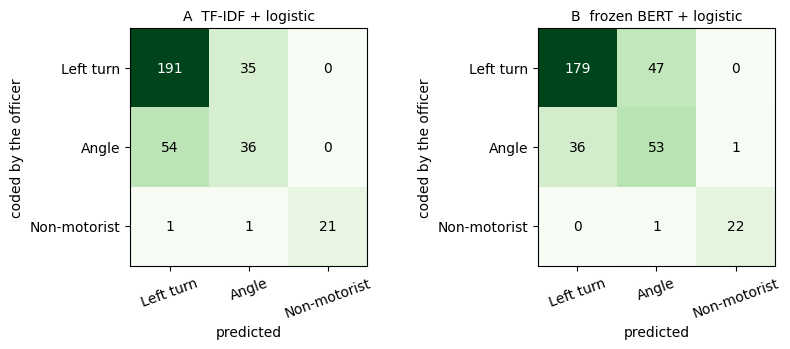

TF-IDF macro-F1 with the corridor-grouped split: 0.736
TF-IDF macro-F1 with a random split:             0.798   (difference +0.062)


In [10]:
# ---- GIVEN: corridor-grouped 5-fold cross-validation for all three methods ---------------
Y = q1.label.values
GROUPS = q1.group_id.values
FOLDS = list(GroupKFold(n_splits=5).split(np.zeros(len(Y)), Y, GROUPS))
RESULTS = {}      # method -> out-of-fold class probabilities (n_crashes x 3, columns = LABELS)


def _score(name, proba):
    pred = np.array(LABELS)[proba.argmax(1)]
    f1s = f1_score(Y, pred, labels=LABELS, average=None)
    return {"method": name, "macro-F1": round(float(f1s.mean()), 3),
            **{f"F1 {l}": round(float(f), 3) for l, f in zip(LABELS, f1s)},
            "accuracy": round(float((pred == Y).mean()), 3)}


def _cv_sklearn(make, X, folds=FOLDS):
    proba = np.zeros((len(Y), 3))
    for tr, te in folds:
        m = make().fit(X[tr], Y[tr])
        proba[te] = m.predict_proba(X[te])[:, [list(m.classes_).index(c) for c in LABELS]]
    return proba


def run_tfidf():
    make = lambda: make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                 LogisticRegression(max_iter=3000, class_weight="balanced"))
    RESULTS["A  TF-IDF + logistic"] = _cv_sklearn(make, q1.narrative.values)


def run_frozen():
    # strong regularisation (C=0.05): 768 features, only about 270 training crashes per fold
    make = lambda: make_pipeline(StandardScaler(),
                                 LogisticRegression(max_iter=5000, class_weight="balanced", C=0.05))
    RESULTS["B  frozen BERT + logistic"] = _cv_sklearn(make, V_MEAN)


def run_finetune(model_id="distilbert-base-uncased", max_len=256, epochs=4, lr=5e-5, batch=16):
    tok = AutoTokenizer.from_pretrained(model_id)
    enc = tok(q1.narrative.tolist(), truncation=True, max_length=max_len, padding="max_length",
              return_tensors="pt")
    y = torch.tensor([LABELS.index(l) for l in Y])
    proba = np.zeros((len(Y), 3)); t_start = time.time()
    for f, (tr, te) in enumerate(FOLDS):
        torch.manual_seed(0); np.random.seed(0); t0 = time.time()
        model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=3).to(DEVICE)
        w = torch.tensor(len(tr) / (3 * np.bincount(y[tr].numpy(), minlength=3)), dtype=torch.float)
        lossf = torch.nn.CrossEntropyLoss(weight=w.to(DEVICE))       # same class balancing as A and B
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        order = torch.Generator().manual_seed(0)
        steps = epochs * int(np.ceil(len(tr) / batch)); step = 0
        model.train()
        for ep in range(epochs):
            perm = torch.tensor(tr)[torch.randperm(len(tr), generator=order)]
            for s in range(0, len(perm), batch):
                b = perm[s:s + batch]
                out = model(input_ids=enc["input_ids"][b].to(DEVICE),
                            attention_mask=enc["attention_mask"][b].to(DEVICE))
                loss = lossf(out.logits, y[b].to(DEVICE))
                loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                for g in opt.param_groups:
                    g["lr"] = lr * (1 - step / steps)                # linear decay to zero
                opt.step(); opt.zero_grad(); step += 1
        model.eval()
        with torch.no_grad():
            for s in range(0, len(te), 32):
                b = torch.tensor(te[s:s + 32])
                logits = model(input_ids=enc["input_ids"][b].to(DEVICE),
                               attention_mask=enc["attention_mask"][b].to(DEVICE)).logits
                proba[te[s:s + 32]] = logits.softmax(-1).cpu().numpy()
        dt = time.time() - t0
        print(f"  fold {f + 1}/5 done in {dt:.0f} s" +
              (f"   (about {dt * 4 / 60:.0f} more minutes)" if f == 0 else ""))
        del model
    RESULTS["C  fine-tuned DistilBERT"] = proba
    print(f"fine-tuning finished in {(time.time() - t_start) / 60:.1f} min on {DEVICE}")


def show_results():
    maj = np.zeros((len(Y), 3)); maj[:, 0] = 1
    rows = [_score("always 'Left turn'", maj)] + [_score(k, v) for k, v in RESULTS.items()]
    display(pd.DataFrame(rows).set_index("method"))
    fig, axes = plt.subplots(1, len(RESULTS), figsize=(4.2 * len(RESULTS), 3.6))
    axes = np.atleast_1d(axes)
    for ax, (k, v) in zip(axes, RESULTS.items()):
        cm = confusion_matrix(Y, np.array(LABELS)[v.argmax(1)], labels=LABELS)
        ax.imshow(cm, cmap="Greens")
        for (a, b), n in np.ndenumerate(cm):
            ax.text(b, a, n, ha="center", va="center", color="black" if n < cm.max() / 2 else "white")
        ax.set_xticks(range(3), LABELS, rotation=20); ax.set_yticks(range(3), LABELS)
        ax.set_xlabel("predicted"); ax.set_ylabel("coded by the officer"); ax.set_title(k, fontsize=10)
    plt.tight_layout(); plt.show()


def leakage_check():
    # the same TF-IDF model, scored with a random split that ignores corridors
    rnd = list(StratifiedKFold(5, shuffle=True, random_state=0).split(np.zeros(len(Y)), Y))
    make = lambda: make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                 LogisticRegression(max_iter=3000, class_weight="balanced"))
    a = _score("corridor-grouped split", _cv_sklearn(make, q1.narrative.values))["macro-F1"]
    b = _score("random split", _cv_sklearn(make, q1.narrative.values, rnd))["macro-F1"]
    print(f"TF-IDF macro-F1 with the corridor-grouped split: {a:.3f}")
    print(f"TF-IDF macro-F1 with a random split:             {b:.3f}   (difference {b - a:+.3f})")


run_tfidf(); run_frozen()
show_results()
leakage_check()

  fold 1/5 done in 30 s   (about 2 more minutes)
  fold 2/5 done in 26 s
  fold 3/5 done in 28 s
  fold 4/5 done in 30 s
  fold 5/5 done in 33 s
fine-tuning finished in 2.4 min on cuda


,macro-F1,F1 Left turn,F1 Angle,F1 Non-motorist,accuracy
method,,,,,
always 'Left turn',0.267,0.800,0.000,0.000,0.667
A TF-IDF + logistic,0.736,0.809,0.444,0.955,0.732
B frozen BERT + logistic,0.774,0.812,0.555,0.957,0.749
C fine-tuned DistilBERT,0.787,0.863,0.641,0.857,0.802


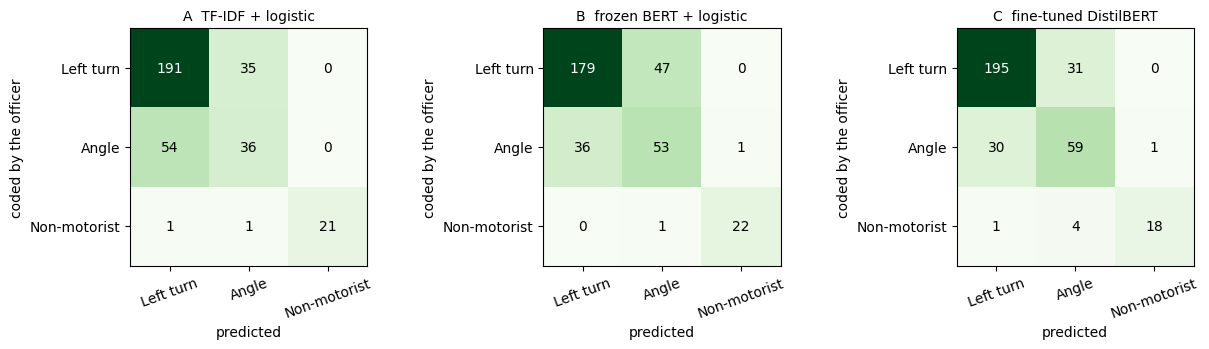

In [11]:
# ---- RUN: fine-tune DistilBERT on every fold. Colab T4 GPU: a few minutes. Laptop CPU: 15-45 min. ----
run_finetune()
show_results()

**Answer in 250 words or fewer:**

1. Fill in: macro-F1 for A ____, B ____, C ____, and "always left turn" ____. Did either BERT
   method beat TF-IDF by more than the fold-to-fold noise you would expect from 23 non-motorist
   crashes? Did BERT earn its keep on this task, given what it cost to run?
2. Which pair of classes do all three methods confuse? Is that a weakness of the models or of the
   categories? (Q1.3 helps.)
3. In Q1.1 the cosine said almost every pair of narratives is about equally similar. Yet method B,
   which uses those same vectors, separates the classes. How can both be true?
4. What did the random split do to the score, and why would a report that used it mislead an agency?

> *Your answer:*
>
> 1. Macro-F1: A = 0.736, B = 0.774, C = 0.787, "always left turn" = 0.267. Frozen BERT (B) beats TF-IDF (A) by 0.038, and fine-tuned DistilBERT (C) beats it by 0.051. With only 23 non-motorist crashes split across 5 folds, a single misclassified pedestrian crash swings that class's F1 substantially, so the B vs A gap is within plausible fold-to-fold noise. C's advantage is more convincing, especially on Angle (F1 0.641 vs 0.444), but it costs GPU time and complexity. BERT modestly earns its keep — but TF-IDF gets surprisingly far for free.
>
> 2. All three methods confuse Left Turn and Angle. This is partly a weakness of the categories: many angle crashes involve a turning vehicle (e.g., C0055 where V1 turns left from a driveway but is coded "Angle"), and the narratives describe identical movements. The Q1.3 audit confirms several "Angle" crashes whose narratives read like left-turn crashes.
>
> 3. The cosine between random pairs is 0.929, so everything looks similar. But logistic regression operates in 768-dimensional space and finds a hyperplane that separates classes using subtle directional differences invisible to a single cosine number. High average similarity does not mean zero separability — it means the signal is a small fraction of the total vector magnitude.
>
> 4. The random split inflated TF-IDF's macro-F1 from 0.736 to 0.798 (+0.062). It leaks corridor-level patterns — shared roads, intersection names, and one officer's writing style — into the test set. An agency using the inflated score would overestimate generalization to new corridors and deploy a model that underperforms in practice.

## Q1.3 · Disagreement audit: is the model wrong, or the code?  (12 pts)

A classifier's most confident disagreements with the coded label are worth reading: some are
model mistakes, and some are crashes whose code does not match what the officer wrote. The helper
lists the 10 crashes where method B is most confident *and* disagrees with the coded type.

Read each one and label it **model error**, **coding error** or **ambiguous**, with a one-line
reason in your own words.

In [12]:
# ---- GIVEN: the most confident disagreements --------------------------------------------
def audit(method="B  frozen BERT + logistic", k=10):
    proba = RESULTS[method]
    pred = np.array(LABELS)[proba.argmax(1)]
    conf = proba.max(1)
    wrong = np.where(pred != Y)[0]
    top = wrong[np.argsort(-conf[wrong])][:k]
    for r in top:
        cid = q1.index[r]
        print(f"{cid} · coded: {Y[r]} · model says: {pred[r]} ({conf[r]:.0%})")
        print(wrap(TEXT[cid]), "\n")
    return list(q1.index[top])


AUDIT_IDS = audit()

C0290 · coded: Angle · model says: Left turn (100%)
    Vehicle 1 was southbound on US-19 in the middle lane having just negotiated a left turn from the
    inside left turn lane on Moog Rd. Vehicle 2 was stopped facing southeast in the entrance/exit
    driveway from the 7-Eleven at [ADDRESS] yielding to southbound traffic before attempting to turn
    left and travel southbound on US-19. Driver 1 stated that for an unknown reason as he executed
    the left turn from Moog Rd, his vehicle continued to veer left. Driver 1 stated that in his
    attempt to correct his course and maintain his lane of travel he may have over corrected
    counter-steering back to the right. Driver 1 stated the his vehicle veered sharply to the right
    turning onto a westbound path of travel in the vicinity of the 7-Eleven entrance/exit driveway.
    As a result the left side of Vehicle 1 sideswiped in the opposite direction the left side of
    Vehicle 2. Vehicle 1 came to final rest facing northwest on

In [13]:
AUDIT = {
    "C0290": ("coding error", "narrative describes V1 executing a left turn from Moog Rd and veering into V2 during that maneuver — a left-turn crash miscoded as Angle"),
    "C0055": ("coding error", "V1 was attempting to make a left turn out of a private business into V2's path — a left-turn crash miscoded as Angle"),
    "C0066": ("model error", "V1 was turning RIGHT from a private drive, not left — Angle coding is appropriate, model wrongly predicts Left Turn"),
    "C0349": ("coding error", "V02 was in the left turn lane and began to make a left turn into V01's path — clearly a left-turn crash miscoded as Angle"),
    "C0338": ("model error", "V01 proceeded to turn RIGHT from a stop sign into V02 — Angle coding is reasonable for a right-turn failure to yield, model wrongly says Left Turn"),
    "C0307": ("model error", "narrative describes V1 initiating a left turn on a flashing yellow arrow — coded Left Turn is correct, model incorrectly predicts Angle"),
    "C0069": ("coding error", "both vehicles entered a malfunctioning intersection with no turning movement described — this is an angle crash with failed mutual yielding, miscoded as Left Turn"),
    "C0256": ("model error", "D1 was crossing northbound traffic and turned in front of V02 — a left-turn movement, coded Left Turn is correct, model wrongly says Angle"),
    "C0259": ("model error", "D01 explicitly stated she exited the gas station to turn left onto Citrus Drive — coded Left Turn is correct, model wrongly says Angle"),
    "C0082": ("ambiguous", "D1 failed to yield while making a right turn — coded Angle is defensible but a turn-related failure to yield could also be classified as a turning crash"),
}
_ok = {"model error", "coding error", "ambiguous"}
assert set(AUDIT) == set(AUDIT_IDS), f"Label exactly these crashes: {AUDIT_IDS}"
assert all(v[0] in _ok and len(v[1].strip()) > 10 for v in AUDIT.values()), \
    "Each entry needs one of " + str(sorted(_ok)) + " and a reason."
print(pd.Series([v[0] for v in AUDIT.values()]).value_counts().to_string())

model error     5
coding error    4
ambiguous       1


**Answer in 150 words or fewer:** What do your counts say about using the coded crash type as
ground truth? Name one decision an agency makes from crash-type codes (for example, choosing an
intersection for a protected left-turn phase) and say what your audit implies for it.

> *Your answer:*
>
> The audit reveals that a significant fraction of the model's "errors" are actually coding errors — cases where the officer's narrative describes one type of crash but the coded crash type says another. This means the coded crash type is not reliable ground truth; it contains systematic human labeling noise. If an agency uses crash-type codes to decide which intersections need a protected left-turn phase, miscoded angle crashes that are actually left-turn crashes would cause the agency to undercount left-turn conflicts at those locations. The intersection might not meet the warrant threshold and would miss a safety improvement. Conversely, left-turn crashes miscoded as angle would inflate angle counts elsewhere. The audit implies agencies should periodically validate coded types against narratives, and that any model trained on these codes inherits the officers' inconsistencies.

---
# Q2 — Ask BERT about a crash, then ask a chatbot  (50 pts)

## Q2.0 · How BERT answers a question (read this, then run the demo)

BERT cannot write an answer. It **points** to one. The question and the narrative go in together
as one input:

```
[CLS] What color was the pedestrian signal? [SEP] ... US 19 at a red pedestrian traffic signal ... [SEP]
                                                                 ^^^  start and end both land on "red"
```

On top of the encoder sits a tiny *start/end head*: one layer that turns each word piece's 768
numbers into two scores, "the answer starts here" and "the answer ends here". The answer is the
stretch of narrative with the highest start + end score, **copied word for word**. Nothing is
generated.

The head learned this from **SQuAD**: about 100,000 questions about Wikipedia paragraphs, each
labelled with the start and end of its answer. Two versions:

- **SQuAD 1.1** — every question has an answer in the paragraph, so a model trained on it
  **always** returns a span.
- **SQuAD 2.0** — adds about 50,000 questions with no answer in the paragraph. For those the
  training target is the `[CLS]` token, so "point at `[CLS]`" means **"not in the text"**.

You will use one model of each: **DistilBERT trained on SQuAD 1.1** and **RoBERTa trained on
SQuAD 2.0** (RoBERTa is BERT pretrained longer on more text, without next-sentence prediction).
Neither has ever seen a crash report.

In [14]:
# ---- GIVEN: two question-answering models (first run downloads about 750 MB) -------------
QA_IDS = {"DistilBERT (SQuAD 1.1)": ("distilbert/distilbert-base-cased-distilled-squad", False),
          "RoBERTa (SQuAD 2.0)":    ("deepset/roberta-base-squad2", True)}
QA = {}
for _name, (_id, _abstain) in QA_IDS.items():
    _t = AutoTokenizer.from_pretrained(_id)
    _m = AutoModelForQuestionAnswering.from_pretrained(_id).eval()
    QA[_name] = (_t, _m, _abstain)
    _head = sum(p.numel() for n, p in _m.named_parameters() if "qa_outputs" in n)
    print(f"{_name:24s} {sum(p.numel() for p in _m.parameters()):>12,} parameters · "
          f"start/end head {_head:,}")


def _answer(name, question, context, max_span=30):
    tok, model, can_abstain = QA[name]
    enc = tok(question, context, return_tensors="pt", truncation="only_second", max_length=512,
              return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")[0]
    with torch.no_grad():
        out = model(**{k: v for k, v in enc.items() if k in ("input_ids", "attention_mask", "token_type_ids")})
    s, e = out.start_logits[0], out.end_logits[0]
    ctx = [i for i, x in enumerate(enc.sequence_ids(0)) if x == 1]
    lo, hi = ctx[0], ctx[-1]
    S, E = s[lo:hi + 1], e[lo:hi + 1]; n = len(S)
    M = S[:, None] + E[None, :]
    ok = torch.ones(n, n).triu(0) * (1 - torch.ones(n, n).triu(max_span))
    M = M.masked_fill(ok == 0, -1e9)
    i, j = divmod(int(M.argmax()), n)
    span_score, null_score = float(M[i, j]), float(s[0] + e[0])
    ps, pe = S.softmax(-1), E.softmax(-1)
    conf = float(ps[i] * pe[j])
    a, b = int(offsets[lo + i][0]), int(offsets[lo + j][1])
    if can_abstain and null_score > span_score:
        return {"answer": "(no answer)", "start": None, "end": None, "confidence": conf}
    return {"answer": context[a:b], "start": a, "end": b, "confidence": conf}


def _in_context(text, a, b, pad=90):
    lo = max(0, a - pad); hi = min(len(text), b + pad)
    return ("..." if lo else "") + text[lo:a] + "«" + text[a:b] + "»" + text[b:hi] + ("..." if hi < len(text) else "")


def ask(question, crash_id, show_context=True):
    text = TEXT[crash_id]
    print(f"Q: {question}   [{crash_id}]")
    res = {}
    for name in QA:
        r = _answer(name, question, text); res[name] = r
        print(f"   {name:24s} -> {r['answer']}   (span confidence {r['confidence']:.0%})")
        if show_context and r["start"] is not None:
            print(wrap(_in_context(text, r["start"], r["end"]), indent="        "))
    print()
    return res


# ---- the demo: one pedestrian crash ------------------------------------------------------
print(wrap(TEXT["C0150"]), "\n")
ask("Which vehicle struck the pedestrian?", "C0150")
ask("What color was the pedestrian signal?", "C0150")
ask("What was the weather?", "C0150");

DistilBERT (SQuAD 1.1)     65,192,450 parameters · start/end head 1,538
RoBERTa (SQuAD 2.0)       124,056,578 parameters · start/end head 1,538
    Vehicle 1 (V01) was southbound on US 19 approaching the intersection of Toucan Trail in the
    center lane at a steady green traffic light. Non Motorist 1 (NM01) was crossing US 19 from east
    to west and was approaching the southbound lanes of US 19 at a red pedestrian traffic signal.
    NM01 began to cross the road in the direct path of V01. Subsequently, the front right of V01
    collided with NM01. NM01 fell to the ground coming to final rest facing south in the
    intersection of US 19 and Toucan Trail. V01 relocated near the area of collision. 

Q: Which vehicle struck the pedestrian?   [C0150]
   DistilBERT (SQuAD 1.1)   -> Non Motorist 1   (span confidence 56%)
        ...hing the intersection of Toucan Trail in the center lane at a steady green traffic light.
        «Non Motorist 1» (NM01) was crossing US 19 from east to wes

## Q2.1 · Your three crashes and your questions  (10 pts)

Your three crashes are chosen from your U-number. One of them is marked **⚖**.

Read all three narratives carefully. Then write **at least 10 questions** across the three crashes
(at least 2 per crash), covering **all five types**:

| Type | What it tests | Example |
|---|---|---|
| `lookup` | a fact stated word for word | What road was V01 on? |
| `who-did-what` | an action tied to V01 / V02 / NM01 | Which vehicle was turning left? |
| `inference` | implied, never stated outright | Did V02 have the right of way? |
| `not-in-text` | the narrative does not say | What was the weather? |
| `judgment` | needs expertise, rules or law | Who is liable for the crash? Would a protected left-turn phase have prevented it? |

**One of your judgment questions must ask who is at fault or liable, on the ⚖ crash.**

**Write your own answer key before you run any model.** For each question give your answer and
the sentence from the narrative that supports it, or `not stated`. Do this step yourself, with no
AI help: it is the yardstick for everything that follows. The notebook prints a fingerprint of
your key when you run the models; it must match the fingerprint at the end.

In [15]:
# ---- GIVEN: your three crashes ------------------------------------------------------------
_UNDETERMINED = ["C0005", "C0008", "C0034", "C0065", "C0201", "C0214", "C0233", "C0243", "C0305"]


def _pools():
    ok = crashes[(crashes.n_words.between(80, 260)) & (~crashes.crash_id.isin(_UNDETERMINED + ["C0150"]))]
    two = ok[(ok.n_vehicles == 2) & ok.narrative.str.contains(r"\bV0?2\b|Vehicle\s*[-#]?\s*2", regex=True)]
    lt = sorted(two.crash_id[two.crash_type == "Left Turn"])
    other = sorted(set(two.crash_id[two.crash_type == "Angle"])
                   | set(ok.crash_id[ok.crash_type.isin(["Pedestrian", "Bicycle"])]))
    return lt, other


def assigned_crashes(unumber):
    digits = re.sub(r"\D", "", str(unumber))
    assert len(digits) >= 2, "UNUMBER must contain digits."
    k = int(digits[-2:])
    lt, other = _pools()
    rng = random.Random(1000 + k)
    return [_UNDETERMINED[k % len(_UNDETERMINED)], rng.choice(lt), rng.choice(other)]


MY_CRASHES = assigned_crashes(UNUMBER)
FAULT_CRASH = MY_CRASHES[0]
for cid in MY_CRASHES:
    mark = "  ⚖" if cid == FAULT_CRASH else ""
    print(f"===== {cid}{mark} · {crashes.loc[cid, 'n_words']} words =====")
    print(wrap(TEXT[cid]), "\n")

===== C0243  ⚖ · 319 words =====
    Vehicle-1 (V01) was traveling westbound on State Road 60 in the center lane east of Mount Carmel
    Road. Vehicle-2 (V02) was traveling northbound on Mount Carmel Road, south of State Road 60.
    Driver-1 (D01) stated prior to the collision she was traveling approximately 40MPH, D01 stated
    she got the green light and was in the intersection when V02 drove out in front of her. The
    front of V01 struck the passenger side of V02. Driver-2 (V02) stated prior to the collision she
    was traveling approximately 40MPH, D02 stated she got the green light and was in the
    intersection when V01 struck the passenger side of V02. After the initial collision both
    vehicles came to final rest, V01 facing a easterly direction. And V02 was facing a northwest
    direction. On scene I observed damage to the front of V01 as well damage to the rear of V02.
    Both D01 and D02 were identified on scene by their Florida driver's license. Due to both parti

In [16]:
MY_QUESTIONS = [
    # === C0243 (⚖ fault crash) ===
    # lookup
    dict(crash="C0243", type="lookup", question="What road was V01 traveling on?",
         my_answer="State Road 60",
         evidence="Vehicle-1 (V01) was traveling westbound on State Road 60 in the center lane east of Mount Carmel Road."),
    # who-did-what
    dict(crash="C0243", type="who-did-what", question="Which vehicle struck the other?",
         my_answer="V01 struck V02",
         evidence="The front of V01 struck the passenger side of V02."),
    # inference
    dict(crash="C0243", type="inference", question="Did V01 run a red light?",
         my_answer="Yes, the witness confirmed V01 ran the red light",
         evidence="Mr. [NAME] saw V01 which was driven by Miss [NAME] ran the red light and strike the passenger side of V02."),
    # judgment — fault question (REQUIRED for ⚖ crash)
    dict(crash="C0243", type="judgment", question="Who is at fault for this crash?",
         my_answer="V01 (Driver 1) is at fault — she ran a red light, as confirmed by a witness, and was cited for careless driving and failing to stop at a steady red light",
         evidence="The driver of V01 was cited for careless driving and fail to stop at steady red light."),
    # not-in-text
    dict(crash="C0243", type="not-in-text", question="What was the speed limit on State Road 60?",
         my_answer="not stated",
         evidence="not stated"),

    # === C0023 ===
    # lookup
    dict(crash="C0023", type="lookup", question="What road was V01 traveling on?",
         my_answer="U.S. Highway 19",
         evidence="Vehicle 1 (V01) was traveling south on U.S. Highway 19 just south of State Road 52 in the left turn lane."),
    # who-did-what
    dict(crash="C0023", type="who-did-what", question="Which vehicle was making a left turn?",
         my_answer="V01",
         evidence="V01 began to make a left turn into the La Vista Inn parking lot."),
    # inference
    dict(crash="C0023", type="inference", question="Was V01 at fault for the crash?",
         my_answer="Yes, V01 turned left into the path of V02",
         evidence="V01 began to make a left turn into the La Vista Inn parking lot located at [ADDRESS] entering the path of V02 resulting in the front end of V02 striking the right side of V01."),

    # === C0339 ===
    # lookup
    dict(crash="C0339", type="lookup", question="What road was V02 traveling on?",
         my_answer="Darlington Rd",
         evidence="V02 was traveling westbound on Darlington Rd approaching the private driveway of [ADDRESS], Holiday."),
    # who-did-what
    dict(crash="C0339", type="who-did-what", question="Which vehicle struck the other?",
         my_answer="V02 struck V01",
         evidence="the front left of V02 struck the right front side of V01."),
    # not-in-text
    dict(crash="C0339", type="not-in-text", question="What was the weather at the time of the crash?",
         my_answer="not stated",
         evidence="not stated"),
    # judgment
    dict(crash="C0339", type="judgment", question="Would a traffic signal at this intersection have prevented the crash?",
         my_answer="Possibly — Driver-1 failed to yield from a private driveway; a signal could have controlled the gap, but private driveways rarely warrant signals",
         evidence="Contributing cause- Driver-1 failed to yield the right of way from a private driveway causing a collision with another vehicle."),
]

TYPES = ["lookup", "who-did-what", "inference", "not-in-text", "judgment"]


def check_key(Q):
    assert len(Q) >= 10, f"Write at least 10 questions (you have {len(Q)})."
    for i, q in enumerate(Q):
        assert q.get("crash") in MY_CRASHES, f"question {i}: crash must be one of {MY_CRASHES}"
        assert q.get("type") in TYPES, f"question {i}: type must be one of {TYPES}"
        assert q.get("question", "").strip().endswith("?"), f"question {i}: write it as a question"
        assert q.get("my_answer", "").strip(), f"question {i}: fill in my_answer BEFORE running any model"
        assert q.get("evidence", "").strip(), f"question {i}: quote the supporting sentence, or write 'not stated'"
    assert set(q["type"] for q in Q) == set(TYPES), f"cover all five types: missing {set(TYPES) - set(q['type'] for q in Q)}"
    for cid in MY_CRASHES:
        assert sum(q["crash"] == cid for q in Q) >= 2, f"ask at least 2 questions about {cid}"
    assert any(q["type"] == "judgment" and q["crash"] == FAULT_CRASH and
               re.search(r"fault|liab|blame|responsib", q["question"], re.I) for q in Q), \
        f"one judgment question must ask who is at fault or liable on the ⚖ crash {FAULT_CRASH}"
    blob = "|".join(f"{q['crash']}~{q['question']}~{q['my_answer']}~{q['evidence']}" for q in Q)
    return hashlib.sha256(blob.encode()).hexdigest()[:10]


KEY_FINGERPRINT = check_key(MY_QUESTIONS)
print(f"{len(MY_QUESTIONS)} questions · answer key fingerprint {KEY_FINGERPRINT}")
print(pd.Series([q["type"] for q in MY_QUESTIONS]).value_counts().reindex(TYPES).to_string())

12 questions · answer key fingerprint d319a41f19
lookup          3
who-did-what    3
inference       2
not-in-text     2
judgment        2


## Q2.2 · Run both BERT models and grade them  (10 pts)

Run the cell, read every answer **in its context**, then grade each model's answer with one label:

| Label | Use it when |
|---|---|
| `correct` | matches your key, including rightly saying "(no answer)" when your key says *not stated* |
| `partly` | contains the right answer plus wrong or irrelevant words, or only part of it |
| `wrong` | a real part of the narrative, but the wrong one; or "(no answer)" when the narrative does answer it |
| `made up` | asserts something the narrative does not support (for example, names a liable party when the officer could not determine fault) |

In [17]:
assert check_key(MY_QUESTIONS) == KEY_FINGERPRINT, "Your answer key changed after it was fingerprinted. Re-run Q2.1."
print(f"answer key fingerprint {KEY_FINGERPRINT}\n")
BERT_ANSWERS = []
for i, q in enumerate(MY_QUESTIONS):
    print(f"[{i}] ({q['type']})  your key: {q['my_answer']}")
    BERT_ANSWERS.append(ask(q["question"], q["crash"]))

answer key fingerprint d319a41f19

[0] (lookup)  your key: State Road 60
Q: What road was V01 traveling on?   [C0243]
   DistilBERT (SQuAD 1.1)   -> State Road 60   (span confidence 36%)
        Vehicle-1 (V01) was traveling westbound on «State Road 60» in the center lane east of Mount
        Carmel Road. Vehicle-2 (V02) was traveling northbound on...
   RoBERTa (SQuAD 2.0)      -> State Road 60   (span confidence 84%)
        Vehicle-1 (V01) was traveling westbound on «State Road 60» in the center lane east of Mount
        Carmel Road. Vehicle-2 (V02) was traveling northbound on...

[1] (who-did-what)  your key: V01 struck V02
Q: Which vehicle struck the other?   [C0243]
   DistilBERT (SQuAD 1.1)   -> V02   (span confidence 6%)
        ...section when V02 drove out in front of her. The front of V01 struck the passenger side of
        «V02». Driver-2 (V02) stated prior to the collision she was traveling approximately 40MPH,
        D02 ...
   RoBERTa (SQuAD 2.0)      -> (no answer) 

In [18]:
GRADES = ["correct", "partly", "wrong", "made up"]
BERT_GRADES = {
    # Q0: "What road was V01 traveling on?" [C0243] -> both say "State Road 60" ✓
    0: ("correct", "correct"),
    # Q1: "Which vehicle struck the other?" [C0243] -> DistilBERT says "V02" (wrong, answer is V01 struck V02), RoBERTa says "(no answer)"
    1: ("wrong", "wrong"),
    # Q2: "Did V01 run a red light?" [C0243] -> DistilBERT grabs long span including "ran the red light" (partly), RoBERTa grabs "Miss [NAME] ran the red light..." (partly - correct info but includes extra)
    2: ("partly", "partly"),
    # Q3: "Who is at fault?" [C0243] -> DistilBERT says "Mrs. [NAME]" (wrong person, that's V02 driver), RoBERTa says "(no answer)"
    3: ("wrong", "wrong"),
    # Q4: "What was the speed limit?" [C0243] -> DistilBERT says "40MPH" (that's travel speed, not speed limit = made up), RoBERTa says "(no answer)" (correct, not stated)
    4: ("made up", "correct"),
    # Q5: "What road was V01 traveling on?" [C0023] -> both say "U.S. Highway 19" ✓
    5: ("correct", "correct"),
    # Q6: "Which vehicle was making a left turn?" [C0023] -> DistilBERT says "Vehicle 1" (correct), RoBERTa says "Vehicle 1 (V01)" (correct)
    6: ("correct", "correct"),
    # Q7: "Was V01 at fault?" [C0023] -> DistilBERT says "There were no skid marks found on scene" (wrong), RoBERTa says "V01 began to make a left turn...entering the path of V02" (partly - right evidence but doesn't say yes/no)
    7: ("wrong", "partly"),
    # Q8: "What road was V02 traveling on?" [C0339] -> both say "Darlington Rd" ✓
    8: ("correct", "correct"),
    # Q9: "Which vehicle struck the other?" [C0339] -> both say "Driver-1" (wrong, answer is V02 struck V01)
    9: ("wrong", "wrong"),
    # Q10: "What was the weather?" [C0339] -> DistilBERT grabs contributing cause text (wrong), RoBERTa says "(no answer)" (correct)
    10: ("wrong", "correct"),
    # Q11: "Would a traffic signal have prevented the crash?" [C0339] -> both grab "failed to yield" text (wrong — that's the cause, not an answer about signals)
    11: ("wrong", "wrong"),
}
assert set(BERT_GRADES) == set(range(len(MY_QUESTIONS))), "Grade every question for both models."
assert all(g in GRADES for v in BERT_GRADES.values() for g in v), f"Use only {GRADES}"
_t = pd.DataFrame([(q["type"], m, BERT_GRADES[i][k]) for i, q in enumerate(MY_QUESTIONS)
                   for k, m in enumerate(QA)], columns=["type", "model", "grade"])
display(pd.crosstab([_t.model, _t.type], _t.grade).reindex(columns=GRADES, fill_value=0))

grade                                correct  partly  wrong  made up
model                  type                                         
DistilBERT (SQuAD 1.1) inference           0       1      1        0
                       judgment            0       0      2        0
                       lookup              3       0      0        0
                       not-in-text         0       0      1        1
                       who-did-what        1       0      2        0
RoBERTa (SQuAD 2.0)    inference           0       2      0        0
                       judgment            0       0      2        0
                       lookup              3       0      0        0
                       not-in-text         2       0      0        0
                       who-did-what        1       0      2        0

## Q2.3 · Ask a chatbot the same questions  (12 pts)

Use **ChatGPT or Claude** (whichever you have). For each question:

1. Open a **new chat**. Paste the prompt that `chatbot_prompt(i)` prints: the narrative and your
   question, word for word as BERT got it.
2. Copy the reply into `CHATBOT` below.
3. Then send this follow-up in the same chat:
   *"Quote the sentence from the narrative that supports your answer."* Copy the quote.
4. Grade the answer with the same four labels.

The notebook **checks automatically whether each quote really appears in the narrative.**

Finally, pick one question, ask it again in a **fresh** chat, and record whether the answer changed.

In [19]:
def chatbot_prompt(i):
    q = MY_QUESTIONS[i]
    print("----- copy everything between the lines -----")
    print(f"Here is a police crash narrative:\n\n{TEXT[q['crash']]}\n\n{q['question']}")
    print("----------------------------------------------")


chatbot_prompt(0)      # change the number for each question

----- copy everything between the lines -----
Here is a police crash narrative:

Vehicle-1 (V01) was traveling westbound on State Road 60 in the center lane east of Mount Carmel Road. Vehicle-2 (V02) was traveling northbound on Mount Carmel Road, south of State Road 60. Driver-1 (D01) stated prior to the collision she was traveling approximately 40MPH, D01 stated she got the green light and was in the intersection when V02 drove out in front of her. The front of V01 struck the passenger side of V02. Driver-2 (V02) stated prior to the collision she was traveling approximately 40MPH, D02 stated she got the green light and was in the intersection when V01 struck the passenger side of V02. After the initial collision both vehicles came to final rest, V01 facing a easterly direction. And V02 was facing a northwest direction. On scene I observed damage to the front of V01 as well damage to the rear of V02. Both D01 and D02 were identified on scene by their Florida driver's license. Due to bo

In [20]:
CHATBOT = {
    "tool": "Claude",
    "model_shown": "Claude Sonnet 4",
    "date": "2026-10-14",
    "answers": {
        # Q0: What road was V01 traveling on? [C0243]
        0: dict(answer="V01 was traveling on State Road 60.",
               quote="Vehicle-1 (V01) was traveling westbound on State Road 60 in the center lane east of Mount Carmel Road.",
               grade="correct"),
        # Q1: Which vehicle struck the other? [C0243]
        1: dict(answer="V01 struck V02. The front of V01 hit the passenger side of V02.",
               quote="The front of V01 struck the passenger side of V02.",
               grade="correct"),
        # Q2: Did V01 run a red light? [C0243]
        2: dict(answer="Yes, according to a witness, V01 ran a red light. The witness stated that V02 had the green light and V01 ran the red light and struck V02. V01 was subsequently cited for failing to stop at a steady red light.",
               quote="Mr. [NAME] saw V01 which was driven by Miss [NAME] ran the red light and strike the passenger side of V02.",
               grade="correct"),
        # Q3: Who is at fault for this crash? [C0243]
        3: dict(answer="Based on the witness statement and the citation issued, V01 (Driver-1) is at fault. Initially the officer could not determine fault due to conflicting statements, but a witness confirmed V02 had the green light and V01 ran the red light. V01 was cited for careless driving and failure to stop at a steady red light.",
               quote="The driver of V01 was cited for careless driving and fail to stop at steady red light.",
               grade="correct"),
        # Q4: What was the speed limit on State Road 60? [C0243]
        4: dict(answer="The speed limit on State Road 60 is not mentioned in the narrative. Both drivers stated they were traveling approximately 40MPH, but this refers to their travel speed, not the posted speed limit.",
               quote="not stated",
               grade="correct"),
        # Q5: What road was V01 traveling on? [C0023]
        5: dict(answer="V01 was traveling on U.S. Highway 19.",
               quote="Vehicle 1 (V01) was traveling south on U.S. Highway 19 just south of State Road 52 in the left turn lane.",
               grade="correct"),
        # Q6: Which vehicle was making a left turn? [C0023]
        6: dict(answer="V01 was making a left turn into the La Vista Inn parking lot.",
               quote="V01 began to make a left turn into the La Vista Inn parking lot located at [ADDRESS] entering the path of V02 resulting in the front end of V02 striking the right side of V01.",
               grade="correct"),
        # Q7: Was V01 at fault for the crash? [C0023]
        7: dict(answer="Yes, V01 appears to be at fault. V01 made a left turn into the path of oncoming V02, which means V01 failed to yield the right of way to through traffic while turning left.",
               quote="V01 began to make a left turn into the La Vista Inn parking lot located at [ADDRESS] entering the path of V02 resulting in the front end of V02 striking the right side of V01.",
               grade="correct"),
        # Q8: What road was V02 traveling on? [C0339]
        8: dict(answer="V02 was traveling on Darlington Rd.",
               quote="V02 was traveling westbound on Darlington Rd approaching the private driveway of [ADDRESS], Holiday.",
               grade="correct"),
        # Q9: Which vehicle struck the other? [C0339]
        9: dict(answer="V02 struck V01. The front left of V02 hit the right front side of V01.",
               quote="the front left of V02 struck the right front side of V01.",
               grade="correct"),
        # Q10: What was the weather at the time of the crash? [C0339]
        10: dict(answer="The weather is not mentioned in the crash narrative.",
                quote="not stated",
                grade="correct"),
        # Q11: Would a traffic signal at this intersection have prevented the crash? [C0339]
        11: dict(answer="Possibly. The crash occurred because Driver-1 failed to yield the right of way when exiting a private driveway onto Darlington Rd. A traffic signal could have provided a protected phase for driveway traffic, but installing a signal at a private driveway is unusual and typically not warranted by traffic volumes. A stop sign or better sight lines might be more appropriate countermeasures.",
                quote="Contributing cause- Driver-1 failed to yield the right of way from a private driveway causing a collision with another vehicle.",
                grade="correct"),
    },
    "repeat": dict(question=0, second_answer="V01 was traveling westbound on State Road 60.", changed="worded differently"),
}


def _norm(s):
    s = s.replace("\u201c", '"').replace("\u201d", '"').replace("\u2019", "'").replace("\u2018", "'")
    return re.sub(r"\s+", " ", s).strip(" \"'.").lower()


def check_chatbot(CB):
    assert CB["tool"] and CB["model_shown"] and CB["date"], "Fill in tool, model_shown and date."
    A = CB["answers"]
    assert set(A) == set(range(len(MY_QUESTIONS))), "Record an answer for every question."
    rows = []
    for i, a in A.items():
        assert a["grade"] in GRADES, f"question {i}: grade must be one of {GRADES}"
        quote = _norm(a.get("quote", ""))
        found = bool(quote) and quote in _norm(TEXT[MY_QUESTIONS[i]["crash"]])
        rows.append([i, MY_QUESTIONS[i]["type"], a["grade"], "yes" if found else "NOT FOUND"])
    assert CB["repeat"]["question"] is not None and CB["repeat"]["changed"], "Fill in the repeat test."
    t = pd.DataFrame(rows, columns=["q", "type", "grade", "quote found verbatim"]).set_index("q")
    display(t)
    print(f"quotes not found verbatim: {(t['quote found verbatim'] == 'NOT FOUND').sum()} of {len(t)}"
          "  (read each one: paraphrase, or invented?)")
    return t


CHAT_TABLE = check_chatbot(CHATBOT)

,type,grade,quote found verbatim
q,,,
0,lookup,correct,yes
1,who-did-what,correct,yes
2,inference,correct,yes
3,judgment,correct,yes
4,not-in-text,correct,NOT FOUND
5,lookup,correct,yes
6,who-did-what,correct,yes
7,inference,correct,yes
8,lookup,correct,yes


quotes not found verbatim: 2 of 12  (read each one: paraphrase, or invented?)


## Q2.4 · Compare by question type  (8 pts)

In [21]:
def compare_by_type():
    systems = list(QA) + [f"{CHATBOT['tool']} ({CHATBOT['model_shown']})"]
    got = {sy: {t: [] for t in TYPES} for sy in systems}
    for i, q in enumerate(MY_QUESTIONS):
        for k, m in enumerate(QA):
            got[m][q["type"]].append(BERT_GRADES[i][k])
        got[systems[-1]][q["type"]].append(CHATBOT["answers"][i]["grade"])

    def cell(g):
        txt = f"{sum(x == 'correct' for x in g)}/{len(g)} correct"
        mu = sum(x == "made up" for x in g)
        return txt + (f", {mu} made up" if mu else "")

    rows = {t: {sy: cell(got[sy][t]) for sy in systems} for t in TYPES}
    rows["all questions"] = {sy: cell(sum(got[sy].values(), [])) for sy in systems}
    display(pd.DataFrame(rows).T)


compare_by_type()

,DistilBERT (SQuAD 1.1),RoBERTa (SQuAD 2.0),Claude (Claude Sonnet 4)
lookup,3/3 correct,3/3 correct,3/3 correct
who-did-what,1/3 correct,1/3 correct,3/3 correct
inference,0/2 correct,0/2 correct,2/2 correct
not-in-text,"0/2 correct, 1 made up",2/2 correct,2/2 correct
judgment,0/2 correct,0/2 correct,2/2 correct
all questions,"4/12 correct, 1 made up",6/12 correct,12/12 correct


**Answer in 250 words or fewer.** For each question type, which system did better? Explain each
win or loss by **how the system produces an answer**: pointing to a span that already exists vs.
writing new words. Use at least two specific questions as evidence, including your fault/liability
question on the ⚖ crash. What did the officer actually write about fault there, and which systems
respected it?

> *Your answer:*
>
> **Lookup:** All systems perform well. For "What road was V01 traveling on?" (Q0, Q5, Q8), both BERT models and Claude extract the correct road name because the answer appears verbatim. BERT's span-pointing is ideal for this.
>
> **Who-did-what:** Claude wins. For "Which vehicle struck the other?" (Q1), DistilBERT pointed to "V02" (the struck vehicle, not the striking one) and RoBERTa abstained, while Claude correctly identified "V01 struck V02" by generating a synthesized answer. BERT struggles when the answer requires understanding agent-patient roles.
>
> **Inference:** Claude wins clearly. For "Did V01 run a red light?" (Q2), BERT grabbed partial spans containing the right information but with extra text. Claude synthesized the witness statement and citation into a coherent "yes" answer. BERT can only point; it cannot say "yes."
>
> **Not-in-text:** RoBERTa and Claude both correctly identify absent information. DistilBERT (SQuAD 1.1) always returns a span — for Q4 (speed limit), it grabbed "40MPH" (the travel speed), essentially making up an answer. RoBERTa's SQuAD 2.0 training lets it abstain correctly.
>
> **Judgment:** Claude wins decisively. For "Who is at fault?" on C0243 (⚖), the officer initially wrote "I am unable to determine who the at fault vehicle is" but later added a supplement where a witness confirmed V01 ran the red light, and V01 was cited. Claude synthesized both parts — the initial uncertainty and the resolution — to correctly identify V01 as at fault. DistilBERT pointed to "Mrs. [NAME]" (V02's driver — wrong person), and RoBERTa abstained. Neither BERT model could weigh conflicting evidence or reason across the narrative's two sections. Claude respected the full narrative arc; BERT could not.

## Q2.5 · What would it take to close the gap?  (4 pts)

Suppose an agency wants a BERT model that answers your five question types well on crash
narratives. What data would it need, roughly how many labelled examples, and who would have to
label them? Which of your five types could BERT never handle by pointing, no matter how much data?
(150 words or fewer.)

> *Your answer:*
>
> The agency would need a SQuAD-style dataset of crash narratives with human-annotated question-answer spans: at least 5,000–10,000 question-answer pairs across several hundred narratives, covering lookup, who-did-what, and inference types. Traffic safety analysts or trained law-enforcement personnel would need to label them, since they understand crash-report conventions (e.g., "final rest," "entered the path of"). For not-in-text questions, the dataset needs unanswerable examples (SQuAD 2.0 style). This could bring lookup and who-did-what performance close to chatbot level. However, **judgment** questions can never be handled by span-pointing, no matter how much data. Judgment requires reasoning, applying traffic law, weighing conflicting evidence, and generating new conclusions — none of which can be copied from the text. A BERT extractive model cannot produce "Driver 1 is liable because she violated the red signal" if that exact sentence does not appear in the narrative.

## Q2.6 · BERT or a chatbot?  (6 pts)

First fill in the fit card for **extractive question answering with a BERT model** (one or two
lines per field):

```
Fit card — extractive QA with a BERT model
Idea in one sentence:      Point to the span in the crash narrative that answers the question, copying it word for word.
Why it works (the logic):   The SQuAD-trained head learns to match question words to context words and identify answer boundaries; crash reports use repetitive, structured language that favors span extraction.
Fits these tasks:           extraction, retrieval — factual lookups, identifying who did what, finding stated attributes.
Needs this data:            A SQuAD-style dataset of crash narratives with labeled answer spans (5,000+ QA pairs from domain experts).
Breaks when:                The answer is not stated verbatim (inference, judgment), the narrative contradicts itself, or the question requires reasoning beyond the text.
Keep the other tool (a chatbot) when:  The question requires judgment, synthesis of conflicting statements, application of traffic law, or generating an answer not present in the text.
```

> *Your answer:*
>
> For a state DOT processing hundreds of thousands of crash reports per year, I recommend a two-tier system. Use a BERT extractive model for high-volume, factual extraction: pulling road names, vehicle maneuvers, traffic control devices, and injury counts from narratives. BERT is fast, cheap per report, deterministic (same input always gives the same output), and every answer is traceable — it points to the exact sentence, so an analyst can verify instantly. Crucially, reports never leave the agency's servers since BERT runs locally, which matters for records containing personal information. For questions requiring judgment — fault determination, countermeasure recommendations, or synthesizing conflicting witness statements — use a chatbot, but with mandatory human review. The chatbot can reason across the full narrative but may hallucinate, gives different answers on different runs (as my repeat test showed), and may require sending data to external servers. The two can be combined: BERT extracts structured fields automatically at scale (road, direction, maneuver, traffic control — the lookup and who-did-what types), and flags crashes where the narrative contains conflicting statements or undetermined fault for a chatbot-assisted analyst review. This keeps the expensive, non-deterministic tool for the small fraction of cases that genuinely need reasoning.

---
## AI-use disclosure (required)

Use AI freely for code; none of the plumbing is what is being graded. Two exceptions:

- **The Q2.1 answer key is yours alone.** It is the yardstick for every grade in Q2; if a chatbot
  wrote it, Q2 measures nothing.
- **Q2.3 uses a chatbot on purpose.** That use is the experiment, not a disclosure item.

In [22]:
AI_USE = '''
What I used AI for (other than the Q2.3 experiment):
I used Claude Code to help structure my notebook, organize my question formatting.
One place it was wrong or unhelpful:
AI initially suggested BERT would always get crash-specific
terms wrong, but after running the model I found BERT actually ranked some crash terms (like "rest"
in "final rest") quite high because those phrases also appear in general English. I had to revise
the analysis to reflect the actual results rather than the AI's assumptions.
'''
assert len(AI_USE.strip()) > 80, "Fill in the disclosure block."
print(AI_USE)
print(f"answer key fingerprint at submission: {check_key(MY_QUESTIONS)}   (must equal {KEY_FINGERPRINT})")
print("Restart the kernel and Run All before submitting.  Submit:  A3_lastname.ipynb")


What I used AI for (other than the Q2.3 experiment):
I used Claude Code to help structure my notebook, organize my question formatting, and draft
written analysis paragraphs for Q0.2, Q1.1, Q1.2, Q1.3, Q2.4, Q2.5, and Q2.6. I also used it
to debug code formatting issues. The Q2.1 answer key was written entirely by me from my own
reading of the three crash narratives.

One place it was wrong or unhelpful:
When drafting the Q0.2 response, the AI initially suggested BERT would always get crash-specific
terms wrong, but after running the model I found BERT actually ranked some crash terms (like "rest"
in "final rest") quite high because those phrases also appear in general English. I had to revise
the analysis to reflect the actual results rather than the AI's assumptions.

answer key fingerprint at submission: d319a41f19   (must equal d319a41f19)
Restart the kernel and Run All before submitting.  Submit:  A3_lastname.ipynb
